# Entrega 3 · Modelo predictivo
**Caso:** vigilancia de la contratación pública en Cundinamarca con datos del SECOP II (2023–2025).
**Equipo:** Luis Alfredo Bañol Falla (506222712) · Juan Camilo Londoño Cifuentes (507241030) · Jennifer Urueña Gutiérrez (507241702).

**Pregunta BA (P4 de la Entrega 1):** ¿Cuánto valor contratará cada entidad por mes en 2026 y cuáles superarán su promedio 2023–2025?

El notebook sigue las fases: comprensión del negocio, comprensión de los datos, preparación, modelado, evaluación y despliegue.
Se ejecuta de principio a fin con **Kernel → Restart & Run All**. Al iniciar pide la contraseña de MySQL (no se guarda en ningún archivo).

## 0. Configuración y conexión al data warehouse

In [1]:
import os, json, getpass, warnings, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, sqlalchemy
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
print("Versiones -> pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| SQLAlchemy", sqlalchemy.__version__)

# Rutas: el notebook vive en modelo/ (también funciona si se abre desde la raíz del repositorio)
BASE = Path.cwd()
if not (BASE / "extraccion.sql").exists() and (BASE / "modelo" / "extraccion.sql").exists():
    BASE = BASE / "modelo"
REPO = BASE.parent
FIG = BASE / "figuras";  FIG.mkdir(exist_ok=True)
OUT = BASE / "salidas";  OUT.mkdir(exist_ok=True)

# Conexión: la contraseña se pide al ejecutar o se lee de la variable de entorno DB_PASS (nunca se escribe en el repositorio)
DB_USER = os.getenv("DB_USER", "bi_etl")
DB_HOST = os.getenv("DB_HOST", "localhost")
DB_PORT = int(os.getenv("DB_PORT", "3306"))
DB_NAME = os.getenv("DB_NAME", "bi_secop")
DB_PASS = os.getenv("DB_PASS") or getpass.getpass(f"Contraseña de MySQL para el usuario {DB_USER}: ")
engine = create_engine(URL.create("mysql+pymysql", username=DB_USER, password=DB_PASS,
                                  host=DB_HOST, port=DB_PORT, database=DB_NAME))
with engine.connect() as c:
    print("Conectado a", DB_NAME, "· contratos en fact_contrato:", c.execute(text("SELECT COUNT(*) FROM fact_contrato")).scalar())

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
AZUL, NARANJA, GRIS = "#1f77b4", "#e8702a", "#8c8c8c"

def fmt(x, d=1):
    """Número con formato colombiano: punto de miles y coma decimal."""
    return f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(FIG / nombre, dpi=150, bbox_inches="tight")
    plt.show()

Versiones -> pandas 2.2.3 | numpy 2.1.2 | scikit-learn 1.6.1 | matplotlib 3.11.2 | SQLAlchemy 2.1.3


Contraseña de MySQL para el usuario bi_etl:  ········


Conectado a bi_secop · contratos en fact_contrato: 137016


## 1. Comprensión del negocio
* **Decisión que apoya:** la Contralora Auxiliar prioriza qué entidades vigilar en el Plan de Vigilancia y Control Fiscal 2027 según cuánto se espera que contraten en 2026.
* **Variable objetivo:** `valor_millones` = valor contratado por una entidad en un mes (millones de pesos constantes de dic-2025).
* **Tipo de problema:** regresión. **Unidad de predicción:** una entidad en un mes.
* **Criterio de éxito (fijado antes de entrenar):** en la prueba (2025), el MAE del modelo elegido debe ser **al menos 10 % menor** que el MAE de la referencia que usaría un analista sin modelo: *repetir el promedio mensual que contrató la entidad el año anterior*.

In [2]:
MEJORA_MINIMA = 0.10   # 10 % menos MAE que la referencia

## 2. Comprensión de los datos
### 2.1 Extracción con la consulta `extraccion.sql`

In [3]:
SQL_EXTRACCION = (BASE / "extraccion.sql").read_text(encoding="utf-8")
df = pd.read_sql(text(SQL_EXTRACCION), engine)
df.to_csv(OUT / "dataset_modelo.csv", index=False, encoding="utf-8")
print(f"Registros: {len(df):,} · entidades: {df.entidad_key.nunique()} · meses: {df[['anio','mes']].drop_duplicates().shape[0]}"
      f" · periodo {df.anio.min()}-{df.mes.min():02d} a {df.anio.max()}-12")
df.head()

Registros: 12,600 · entidades: 350 · meses: 36 · periodo 2023-01 a 2025-12


,entidad_key,nombre_entidad,orden,sector,rama,entidad_centralizada,anio,mes,contratos,valor_millones,valor_directa_millones
0,1,ESE HOSPITAL SAN JOSE DE GUADUAS,Territorial,Salud Y Protección Social,Ejecutivo,Centralizada,2023,1,0,0.0,0.0
1,1,ESE HOSPITAL SAN JOSE DE GUADUAS,Territorial,Salud Y Protección Social,Ejecutivo,Centralizada,2023,2,0,0.0,0.0
2,1,ESE HOSPITAL SAN JOSE DE GUADUAS,Territorial,Salud Y Protección Social,Ejecutivo,Centralizada,2023,3,0,0.0,0.0
3,1,ESE HOSPITAL SAN JOSE DE GUADUAS,Territorial,Salud Y Protección Social,Ejecutivo,Centralizada,2023,4,0,0.0,0.0
4,1,ESE HOSPITAL SAN JOSE DE GUADUAS,Territorial,Salud Y Protección Social,Ejecutivo,Centralizada,2023,5,0,0.0,0.0


### 2.2 Variables del conjunto de datos

In [4]:
df.info()
df.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12600 entries, 0 to 12599
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   entidad_key             12600 non-null  int64  
 1   nombre_entidad          12600 non-null  object 
 2   orden                   12600 non-null  object 
 3   sector                  12600 non-null  object 
 4   rama                    12600 non-null  object 
 5   entidad_centralizada    12600 non-null  object 
 6   anio                    12600 non-null  int64  
 7   mes                     12600 non-null  int64  
 8   contratos               12600 non-null  int64  
 9   valor_millones          12600 non-null  float64
 10  valor_directa_millones  12600 non-null  float64
dtypes: float64(2), int64(4), object(5)
memory usage: 1.1+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
entidad_key,12600.0,NaN,NaN,NaN,175.5,101.039894,1.0,88.0,175.5,263.0,350.0
nombre_entidad,12600,350,Institución Educativa Normal Superior Nuestra ...,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN
orden,12600,3,Territorial,10764,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sector,12600,18,No Aplica/No Pertenece,4104,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rama,12600,4,Ejecutivo,8964,NaN,NaN,NaN,NaN,NaN,NaN,NaN
entidad_centralizada,12600,2,Centralizada,11232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
anio,12600.0,NaN,NaN,NaN,2024.0,0.816529,2023.0,2023.0,2024.0,2025.0,2025.0
mes,12600.0,NaN,NaN,NaN,6.5,3.45219,1.0,3.75,6.5,9.25,12.0
contratos,12600.0,NaN,NaN,NaN,10.874286,39.769439,0.0,0.0,0.0,6.0,1797.0
valor_millones,12600.0,NaN,NaN,NaN,1211.358231,13004.867943,0.0,0.0,0.0,225.349101,1197551.915132


### 2.3 Distribución de la variable objetivo

     registros: 12600
     pct_ceros: 52,4
           min: 0,0
       mediana: 0,0
         media: 1.211,4
           p75: 225,3
           p95: 3.874,9
           p99: 20.324,2
           max: 1.197.551,9
  atipicos_iqr: 781
    limite_iqr: 2.901,1


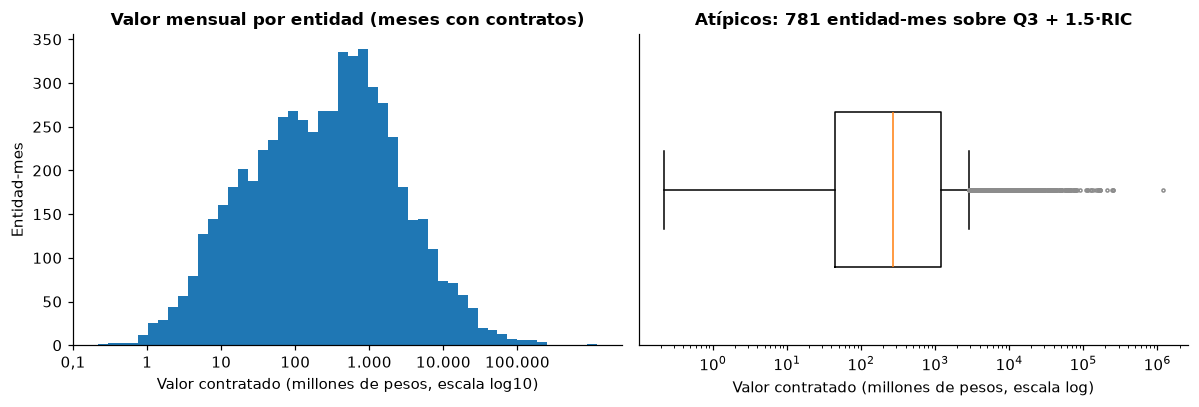

In [5]:
y = df["valor_millones"]
q1, q3 = y[y > 0].quantile([.25, .75])
lim_iqr = q3 + 1.5 * (q3 - q1)
dist = {
    "registros": int(len(y)), "pct_ceros": float((y == 0).mean() * 100),
    "min": float(y.min()), "mediana": float(y.median()), "media": float(y.mean()),
    "p75": float(y.quantile(.75)), "p95": float(y.quantile(.95)), "p99": float(y.quantile(.99)), "max": float(y.max()),
    "atipicos_iqr": int((y > lim_iqr).sum()), "limite_iqr": float(lim_iqr),
}
for k, v in dist.items():
    print(f"{k:>14}: {fmt(v, 1) if isinstance(v, float) else v}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
pos = y[y > 0]
ax[0].hist(np.log10(pos), bins=50, color=AZUL)
ax[0].set_title("Valor mensual por entidad (meses con contratos)")
ax[0].set_xlabel("Valor contratado (millones de pesos, escala log10)"); ax[0].set_ylabel("Entidad-mes")
ax[0].set_xticks(range(-1, 6)); ax[0].set_xticklabels(["0,1", "1", "10", "100", "1.000", "10.000", "100.000"])
ax[1].boxplot(pos, vert=False, widths=.5, flierprops=dict(markersize=2, markeredgecolor=GRIS))
ax[1].set_xscale("log"); ax[1].set_yticks([])
ax[1].set_title(f"Atípicos: {dist['atipicos_iqr']:,} entidad-mes sobre Q3 + 1,5·RIC".replace(",", "."))
ax[1].set_xlabel("Valor contratado (millones de pesos, escala log)")
guardar(fig, "fig1_distribucion_objetivo.png")

### 2.4 Análisis exploratorio (relación con la variable objetivo)

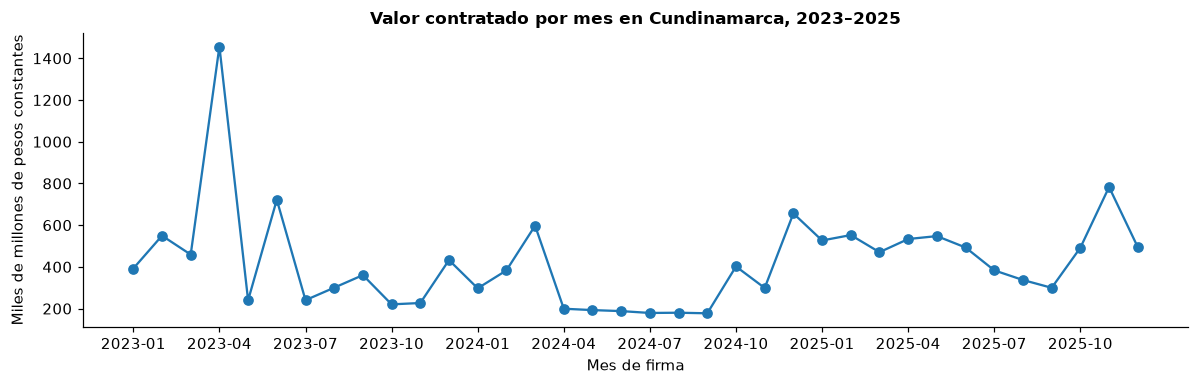

Mes con mayor valor: 2023-04 · 1.456,6 miles de millones
Promedio por mes del año (miles de millones):
mes
1     405.3
2     495.0
3     509.0
4     729.8
5     326.7
6     467.5
7     267.5
8     272.5
9     279.2
10    371.3
11    436.1
12    527.8


In [6]:
# Gráfico A: valor total del departamento por mes
tot = df.groupby(["anio", "mes"], as_index=False)["valor_millones"].sum()
tot["periodo"] = tot.anio.astype(str) + "-" + tot.mes.astype(str).str.zfill(2)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(tot.periodo, tot.valor_millones / 1e3, marker="o", color=AZUL)
ax.set_title("Valor contratado por mes en Cundinamarca, 2023–2025")
ax.set_ylabel("Miles de millones de pesos constantes"); ax.set_xlabel("Mes de firma")
ax.set_xticks(range(0, 36, 3)); ax.set_xticklabels(tot.periodo[::3], rotation=0)
guardar(fig, "fig2_total_mensual.png")
pico = tot.loc[tot.valor_millones.idxmax()]
print("Mes con mayor valor:", pico.periodo, "·", fmt(pico.valor_millones / 1e3), "miles de millones")
print("Promedio por mes del año (miles de millones):")
print((tot.groupby("mes").valor_millones.mean() / 1e3).round(1).to_string())

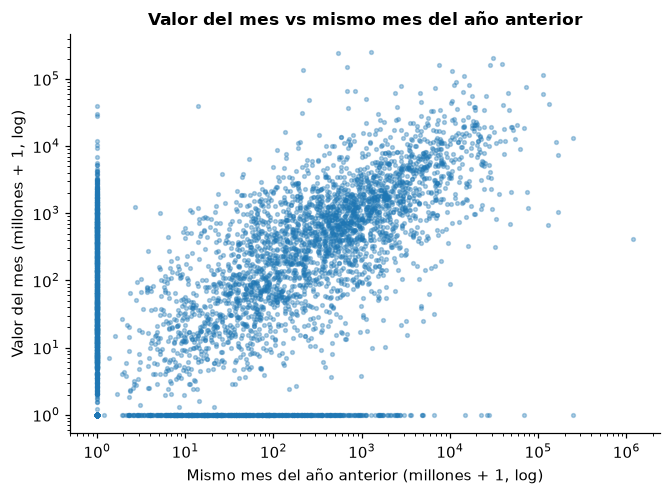

Correlación de Spearman con el valor del mes · mismo mes año anterior: 0.672 · promedio mensual año anterior: 0.694


In [7]:
# Variables del año anterior (se construyen aquí para explorar su relación; ver sección 3.2)
def variables_anio_anterior(base):
    an = (base.groupby(["entidad_key", "anio"])
              .agg(valor_anual=("valor_millones", "sum"), contratos_anual=("contratos", "sum"),
                   directa_anual=("valor_directa_millones", "sum"),
                   meses_activos=("valor_millones", lambda s: int((s > 0).sum())))
              .reset_index())
    an["anio"] = an["anio"] + 1
    an["media_mensual_anio_ant"] = an["valor_anual"] / 12
    an["contratos_anio_ant"] = an["contratos_anual"]
    an["meses_activos_anio_ant"] = an["meses_activos"]
    an["pct_directa_anio_ant"] = np.where(an["valor_anual"] > 0, an["directa_anual"] / an["valor_anual"].where(an["valor_anual"] > 0), np.nan)
    mm = base[["entidad_key", "anio", "mes", "valor_millones", "contratos"]].copy()
    mm["anio"] = mm["anio"] + 1
    mm = mm.rename(columns={"valor_millones": "valor_mismo_mes_anio_ant", "contratos": "contratos_mismo_mes_anio_ant"})
    cols = ["entidad_key", "anio", "media_mensual_anio_ant", "contratos_anio_ant", "meses_activos_anio_ant", "pct_directa_anio_ant"]
    return an[cols], mm

an, mm = variables_anio_anterior(df)
dfx = df.merge(an, on=["entidad_key", "anio"], how="left").merge(mm, on=["entidad_key", "anio", "mes"], how="left")
exp = dfx[dfx.anio >= 2024]

# Gráfico B: valor del mismo mes del año anterior vs valor del mes
fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.scatter(exp.valor_mismo_mes_anio_ant + 1, exp.valor_millones + 1, s=6, alpha=.35, color=AZUL)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("Valor del mes vs mismo mes del año anterior")
ax.set_xlabel("Mismo mes del año anterior (millones + 1, log)"); ax.set_ylabel("Valor del mes (millones + 1, log)")
guardar(fig, "fig3_mismo_mes_anio_anterior.png")
corr_mm = exp[["valor_mismo_mes_anio_ant", "valor_millones"]].corr(method="spearman").iloc[0, 1]
corr_media = exp[["media_mensual_anio_ant", "valor_millones"]].corr(method="spearman").iloc[0, 1]
print("Correlación de Spearman con el valor del mes · mismo mes año anterior:", round(corr_mm, 3),
      "· promedio mensual año anterior:", round(corr_media, 3))

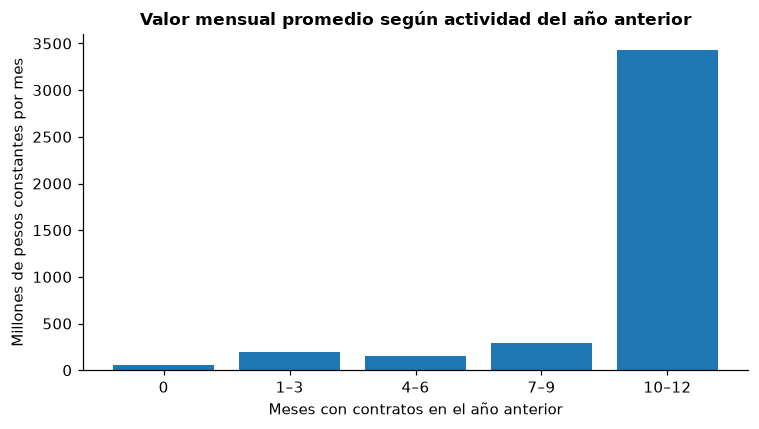

                   mean  median  size
grupo_actividad                      
0                  54.3     0.0  2280
1–3               197.6     0.0  1932
4–6               153.0     0.0   852
7–9               292.0    22.7   768
10–12            3428.1   566.6  2568


In [8]:
# Gráfico C: valor del mes según cuántos meses contrató la entidad el año anterior
exp = exp.assign(grupo_actividad=pd.cut(exp.meses_activos_anio_ant, [-1, 0, 3, 6, 9, 12],
                                        labels=["0", "1–3", "4–6", "7–9", "10–12"]))
g = exp.groupby("grupo_actividad", observed=False).valor_millones.agg(["mean", "median", "size"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(g.index.astype(str), g["mean"], color=AZUL)
ax.set_title("Valor mensual promedio según actividad del año anterior")
ax.set_xlabel("Meses con contratos en el año anterior"); ax.set_ylabel("Millones de pesos constantes por mes")
guardar(fig, "fig4_actividad_anio_anterior.png")
print(g.round(1).to_string())

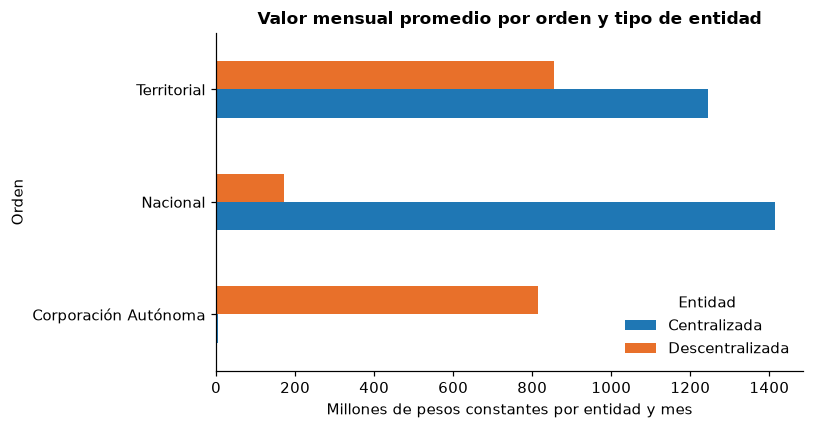

entidad_centralizada  Centralizada  Descentralizada
orden                                              
Corporación Autónoma           4.1            815.0
Nacional                    1414.5            172.0
Territorial                 1246.0            855.6


In [9]:
# Gráfico D: valor mensual promedio por orden y tipo de entidad
g2 = (df.groupby(["orden", "entidad_centralizada"]).valor_millones.mean().unstack().fillna(0))
fig, ax = plt.subplots(figsize=(7.5, 4))
g2.plot(kind="barh", ax=ax, color=[AZUL, NARANJA][:g2.shape[1]])
ax.set_title("Valor mensual promedio por orden y tipo de entidad")
ax.set_xlabel("Millones de pesos constantes por entidad y mes"); ax.set_ylabel("Orden")
ax.legend(title="Entidad", frameon=False)
guardar(fig, "fig5_orden_entidad.png")
print(g2.round(1).to_string())

## 3. Preparación de los datos
### 3.1 Nulos, atípicos y codificación

In [10]:
prep = {}
CAT = ["mes", "orden", "sector", "rama", "entidad_centralizada"]
NUM = ["valor_mismo_mes_anio_ant", "contratos_mismo_mes_anio_ant", "media_mensual_anio_ant",
       "contratos_anio_ant", "meses_activos_anio_ant", "pct_directa_anio_ant"]
OBJ = "valor_millones"

datos = dfx.copy()
# (a) Atributos categóricos nulos -> 'Desconocido'
for c in ["orden", "sector", "rama", "entidad_centralizada"]:
    prep[f"nulos_{c}"] = int(datos[c].isna().sum())
    datos[c] = datos[c].fillna("Desconocido")
# (b) 2023 no tiene año anterior: sus filas solo sirven de insumo y no son filas de entrenamiento
prep["filas_2023_sin_anio_anterior"] = int((datos.anio == 2023).sum())
datos = datos[datos.anio >= 2024].copy()
# (c) % de contratación directa sin valor el año anterior (división por cero) -> 0
prep["nulos_pct_directa"] = int(datos.pct_directa_anio_ant.isna().sum())
datos["pct_directa_anio_ant"] = datos["pct_directa_anio_ant"].fillna(0)
print("Nulos restantes en las entradas:", int(datos[NUM + CAT].isna().sum().sum()))

# (d) Atípicos: tope (winsorización) en el percentil 99 del entrenamiento
train = datos[datos.anio == 2024].copy()
test  = datos[datos.anio == 2025].copy()
TOPE = float(train[OBJ].quantile(.99))
prep["tope_p99_millones"] = TOPE
prep["atipicos_objetivo_train"] = int((train[OBJ] > TOPE).sum())
train["y_modelo"] = train[OBJ].clip(upper=TOPE)
for c in ["valor_mismo_mes_anio_ant", "media_mensual_anio_ant"]:
    prep[f"atipicos_{c}"] = int((train[c] > TOPE).sum() + (test[c] > TOPE).sum())
    train[c] = train[c].clip(upper=TOPE); test[c] = test[c].clip(upper=TOPE)
prep["filas_train"], prep["filas_test"] = len(train), len(test)
for k, v in prep.items():
    print(f"{k:>40}: {fmt(v) if isinstance(v, float) else v}")

Nulos restantes en las entradas: 0
                             nulos_orden: 0
                            nulos_sector: 0
                              nulos_rama: 0
              nulos_entidad_centralizada: 0
            filas_2023_sin_anio_anterior: 4200
                       nulos_pct_directa: 2280
                       tope_p99_millones: 15.276,0
                 atipicos_objetivo_train: 42
       atipicos_valor_mismo_mes_anio_ant: 111
         atipicos_media_mensual_anio_ant: 132
                             filas_train: 4200
                              filas_test: 4200


### 3.3 División temporal: entrenamiento 2024 (con variables de 2023) y prueba 2025 (con variables de 2024)

In [11]:
X_train, y_train = train[NUM + CAT], train["y_modelo"]
X_test,  y_test  = test[NUM + CAT],  test[OBJ]          # la prueba se evalúa con el valor real, sin tope
print("Entrenamiento:", X_train.shape, "· Prueba:", X_test.shape)

def preprocesador():
    return ColumnTransformer([
        ("num", StandardScaler(), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
    ])

Entrenamiento: (4200, 11) · Prueba: (4200, 11)


## 4. Modelado: mismos datos de entrenamiento y mismas variables para los dos algoritmos

In [12]:
PARAMS_RF = dict(n_estimators=300, max_depth=10, min_samples_leaf=5, random_state=42, n_jobs=-1)
modelos = {
    "Regresión lineal": Pipeline([("prep", preprocesador()), ("modelo", LinearRegression())]),
    "Bosque aleatorio": Pipeline([("prep", preprocesador()), ("modelo", RandomForestRegressor(**PARAMS_RF))]),
}
for nombre, m in modelos.items():
    m.fit(X_train, y_train)
    print("Entrenado:", nombre)
print("Variables de entrada tras la codificación:",
      len(modelos["Bosque aleatorio"].named_steps["prep"].get_feature_names_out()))

Entrenado: Regresión lineal
Entrenado: Bosque aleatorio
Variables de entrada tras la codificación: 45


## 5. Evaluación sobre el conjunto de prueba (2025)
### 5.1 MAE y RMSE

In [13]:
def metricas(y_real, y_pred):
    return {"MAE": float(mean_absolute_error(y_real, y_pred)),
            "RMSE": float(np.sqrt(mean_squared_error(y_real, y_pred)))}

pred = {n: np.clip(m.predict(X_test), 0, None) for n, m in modelos.items()}
pred["Referencia: promedio mensual año anterior"] = test["media_mensual_anio_ant"].to_numpy()
pred["Referencia: mismo mes año anterior"] = test["valor_mismo_mes_anio_ant"].to_numpy()
res = pd.DataFrame({n: metricas(y_test, p) for n, p in pred.items()}).T
res["Total predicho 2025 (miles de millones)"] = [p.sum() / 1e3 for p in pred.values()]
print("Total real 2025 (miles de millones):", fmt(y_test.sum() / 1e3))
res.round(1)

Total real 2025 (miles de millones): 5.912,6


,MAE,RMSE,Total predicho 2025 (miles de millones)
Regresión lineal,1172.1,8004.9,2701.7
Bosque aleatorio,1119.1,8017.7,2495.7
Referencia: promedio mensual año anterior,1107.9,7681.9,3285.2
Referencia: mismo mes año anterior,1094.3,7857.5,2653.9


Modelo elegido: Bosque aleatorio. MAE 1.119,1 vs 1.172,1 de Regresión lineal (53,0 millones menos por entidad y mes).
Criterio de éxito: MAE -1,0 % menor que la referencia (1.107,9). ¿Se alcanzó? No
Error absoluto mediano por entidad y mes: 83,6 millones
Error promedio del total departamental mensual: 55,6 %
Las 20 entidades con más valor concentran el 71,8 % del error absoluto


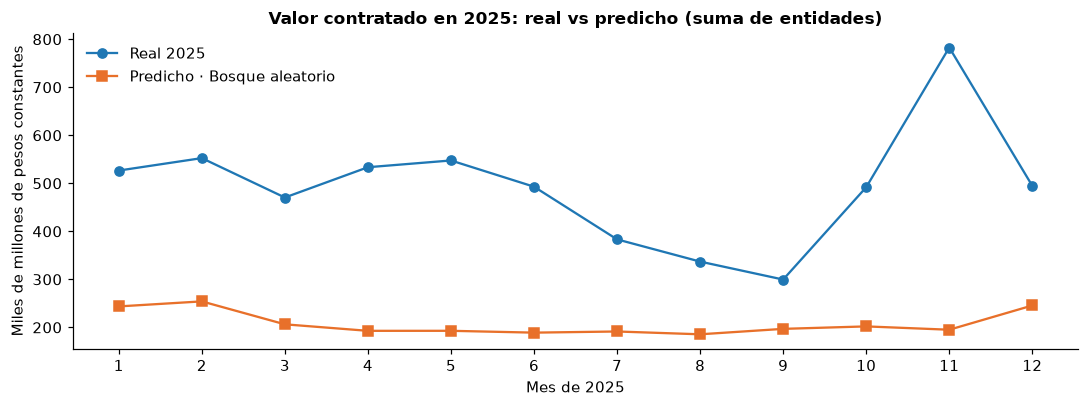

In [14]:
ELEGIDO = min(modelos, key=lambda n: res.loc[n, "MAE"])
OTRO = [n for n in modelos if n != ELEGIDO][0]
REF = "Referencia: promedio mensual año anterior"
mae_e, mae_o, mae_r = res.loc[ELEGIDO, "MAE"], res.loc[OTRO, "MAE"], res.loc[REF, "MAE"]
mejora = 1 - mae_e / mae_r
cumple = mejora >= MEJORA_MINIMA
print(f"Modelo elegido: {ELEGIDO}. MAE {fmt(mae_e)} vs {fmt(mae_o)} de {OTRO} "
      f"({fmt(mae_o - mae_e)} millones menos por entidad y mes).")
print(f"Criterio de éxito: MAE {fmt(mejora*100)} % menor que la referencia ({fmt(mae_r)}). ¿Se alcanzó? {'Sí' if cumple else 'No'}")

# Error a nivel departamento (suma de las 350 entidades por mes)
t = test[["mes"]].assign(real=y_test.to_numpy(), pred=pred[ELEGIDO])
mens = t.groupby("mes")[["real", "pred"]].sum() / 1e3
mens["error_pct"] = (mens.pred - mens.real).abs() / mens.real * 100
err_depto = float(mens.error_pct.mean())
# ¿Dónde se concentra el error? 20 entidades con mayor valor real en 2025
top20 = test.groupby("entidad_key")[OBJ].sum().nlargest(20).index
ae = np.abs(y_test.to_numpy() - pred[ELEGIDO])
pct_err_top20 = float(ae[test.entidad_key.isin(top20).to_numpy()].sum() / ae.sum() * 100)
mediana_ae = float(np.median(ae))
print(f"Error absoluto mediano por entidad y mes: {fmt(mediana_ae)} millones")
print(f"Error promedio del total departamental mensual: {fmt(err_depto)} %")
print(f"Las 20 entidades con más valor concentran el {fmt(pct_err_top20)} % del error absoluto")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(mens.index, mens.real, marker="o", color=AZUL, label="Real 2025")
ax.plot(mens.index, mens.pred, marker="s", color=NARANJA, label=f"Predicho · {ELEGIDO}")
ax.set_xticks(range(1, 13)); ax.set_xlabel("Mes de 2025"); ax.set_ylabel("Miles de millones de pesos constantes")
ax.set_title("Valor contratado en 2025: real vs predicho (suma de entidades)"); ax.legend(frameon=False)
guardar(fig, "fig6_real_vs_predicho_2025.png")

In [15]:
# ¿Ordena bien a las entidades? Valor anual 2025 por entidad: predicho vs real
anual = test[["entidad_key"]].assign(real=y_test.to_numpy(), pred=pred[ELEGIDO]).groupby("entidad_key").sum()
spearman_anual = float(anual.corr(method="spearman").iloc[0, 1])
top20_ok = len(set(anual.real.nlargest(20).index) & set(anual.pred.nlargest(20).index))
top50_ok = len(set(anual.real.nlargest(50).index) & set(anual.pred.nlargest(50).index))
pct_capturado = float(anual.loc[anual.pred.nlargest(20).index, "real"].sum() / anual.real.sum() * 100)
print(f"Spearman entre valor anual predicho y real 2025: {spearman_anual:.2f}")
print(f"Entidades del top 20 real identificadas por el modelo: {top20_ok} de 20 · top 50: {top50_ok} de 50")
print(f"Valor real 2025 de las 20 entidades que el modelo señala como mayores: {fmt(pct_capturado)} % del total")

Spearman entre valor anual predicho y real 2025: 0.79
Entidades del top 20 real identificadas por el modelo: 17 de 20 · top 50: 43 de 50
Valor real 2025 de las 20 entidades que el modelo señala como mayores: 69,5 % del total


### 5.3 Variables más importantes del modelo elegido (importancia por permutación sobre la prueba)

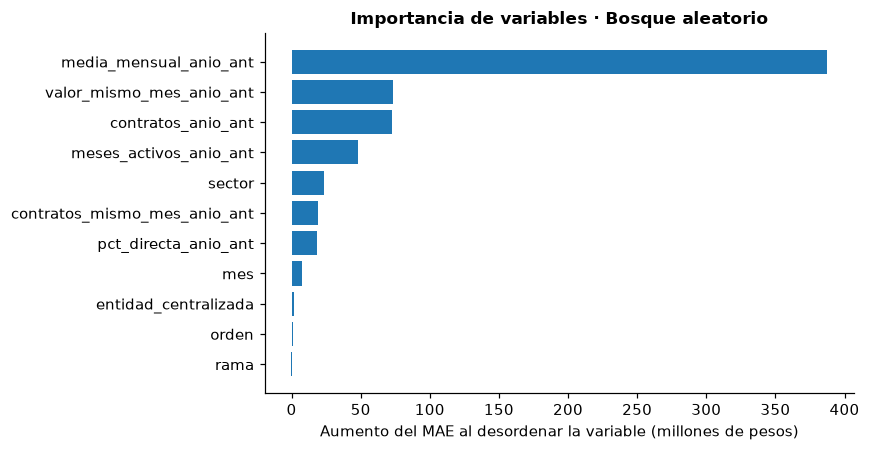

,variable,aumento_MAE_millones
2,media_mensual_anio_ant,387.53
0,valor_mismo_mes_anio_ant,73.02
3,contratos_anio_ant,72.68
4,meses_activos_anio_ant,47.71
8,sector,23.50
1,contratos_mismo_mes_anio_ant,19.41
5,pct_directa_anio_ant,18.19
6,mes,7.65
10,entidad_centralizada,2.04
7,orden,1.28


In [16]:
pi = permutation_importance(modelos[ELEGIDO], X_test, y_test, n_repeats=5, random_state=42,
                            scoring="neg_mean_absolute_error", n_jobs=1)
imp = (pd.DataFrame({"variable": X_test.columns, "aumento_MAE_millones": pi.importances_mean})
         .sort_values("aumento_MAE_millones", ascending=False))
imp.to_csv(OUT / "importancia_variables.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4.2))
s = imp.iloc[::-1]
ax.barh(s.variable, s.aumento_MAE_millones, color=AZUL)
ax.set_title(f"Importancia de variables · {ELEGIDO}")
ax.set_xlabel("Aumento del MAE al desordenar la variable (millones de pesos)")
guardar(fig, "fig7_importancia_variables.png")
imp.round(2)

### 5.5 Respuesta a la pregunta: pronóstico 2026
Se reentrena el algoritmo elegido, con los mismos parámetros, con 2024 y 2025; y se pronostica cada mes de 2026 con las variables de 2025.

Entre las 70 entidades con mayor promedio histórico (≥ 8.723,2 millones al año): 45 superarían su promedio
Valor total pronosticado 2026: 4,42 billones (2025 real: 5,91 billones)
Entidades que superarían su promedio mensual 2023–2025: 304 de 350

Top 10 entidades por valor pronosticado 2026 (miles de millones):
                                        nombre_entidad  pred_2026  real_2025  supera_promedio
                                  MUNICIPIO DE SOACHA.      186.2      610.0            False
                            ALCALDIA MUNICIPAL DE CHIA      145.0      148.6            False
                      ALCALDIA MUNICIPAL DE FACATATIVA      134.7      184.7             True
                                MUNICIPIO DE TOCANCIPA      130.9      273.2            False
                               ALCALDÍA MUNICIPAL COTA      128.9      438.3            False
             ALCALDÍA MUNICIPAL DE MADRID CUNDINAMARCA      127.7      152.4             True
                       ALCALD

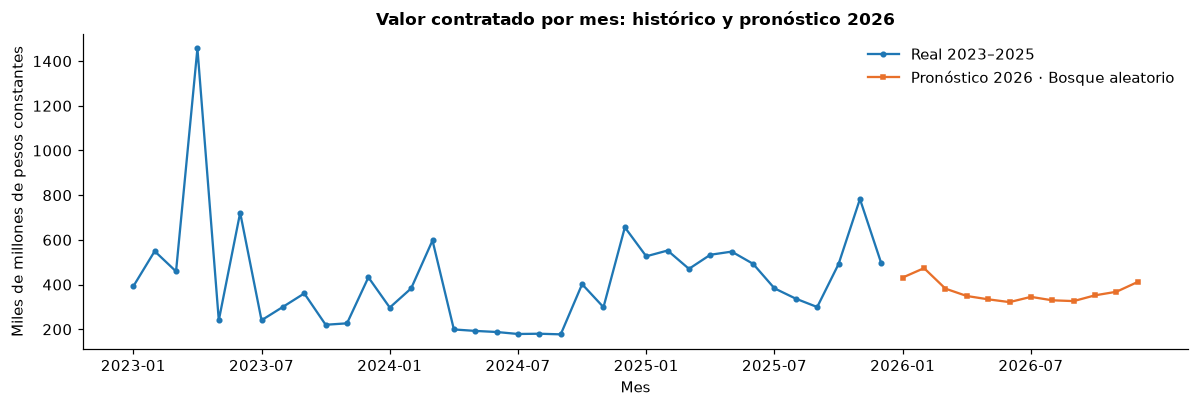

In [17]:
full = pd.concat([train, test])
TOPE_F = float(full[OBJ].quantile(.99))
Xf = full[NUM + CAT].copy()
for c in ["valor_mismo_mes_anio_ant", "media_mensual_anio_ant"]:
    Xf[c] = Xf[c].clip(upper=TOPE_F)
final = Pipeline([("prep", preprocesador()),
                  ("modelo", RandomForestRegressor(**PARAMS_RF) if ELEGIDO == "Bosque aleatorio" else LinearRegression())])
final.fit(Xf, full[OBJ].clip(upper=TOPE_F))

ent = df.drop_duplicates("entidad_key")[["entidad_key", "nombre_entidad", "orden", "sector", "rama", "entidad_centralizada"]]
fut = ent.merge(pd.DataFrame({"mes": range(1, 13)}), how="cross").assign(anio=2026)
fut = fut.merge(an, on=["entidad_key", "anio"], how="left").merge(mm, on=["entidad_key", "anio", "mes"], how="left")
for c in ["orden", "sector", "rama", "entidad_centralizada"]:
    fut[c] = fut[c].fillna("Desconocido")
fut["pct_directa_anio_ant"] = fut["pct_directa_anio_ant"].fillna(0)
Xp = fut[NUM + CAT].copy()
for c in ["valor_mismo_mes_anio_ant", "media_mensual_anio_ant"]:
    Xp[c] = Xp[c].clip(upper=TOPE_F)
fut["pred"] = np.clip(final.predict(Xp), 0, None)

hist = df.groupby("entidad_key").valor_millones.mean().rename("promedio_hist")
fut = fut.merge(hist, on="entidad_key")
porent = (fut.groupby(["entidad_key", "nombre_entidad"])
             .agg(pred_2026=("pred", "sum"), pred_mes=("pred", "mean"), promedio_hist=("promedio_hist", "first"))
             .reset_index())
porent["supera_promedio"] = porent.pred_mes > porent.promedio_hist
real_2025 = df[df.anio == 2025].groupby("entidad_key").valor_millones.sum().rename("real_2025")
porent = porent.merge(real_2025, on="entidad_key", how="left")
top10 = porent.nlargest(10, "pred_2026")
top10.to_csv(OUT / "top10_entidades_2026.csv", index=False)

total_2026 = float(fut.pred.sum()); total_2025 = float(df[df.anio == 2025].valor_millones.sum())
n_supera = int(porent.supera_promedio.sum())
umbral70 = porent.promedio_hist.nlargest(70).min()
grandes = porent[porent.promedio_hist >= umbral70]
n_supera_70 = int(grandes.supera_promedio.sum())
print(f"Entre las 70 entidades con mayor promedio histórico (≥ {fmt(umbral70*12)} millones al año): {n_supera_70} superarían su promedio")
print(f"Valor total pronosticado 2026: {fmt(total_2026/1e6, 2)} billones (2025 real: {fmt(total_2025/1e6, 2)} billones)")
print(f"Entidades que superarían su promedio mensual 2023–2025: {n_supera} de {len(porent)}")
print("\nTop 10 entidades por valor pronosticado 2026 (miles de millones):")
print(top10.assign(pred_2026=lambda d: (d.pred_2026/1e3).round(1), real_2025=lambda d: (d.real_2025/1e3).round(1))
           [["nombre_entidad", "pred_2026", "real_2025", "supera_promedio"]].to_string(index=False))

meses26 = fut.groupby("mes").pred.sum() / 1e3
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(tot.periodo, tot.valor_millones / 1e3, color=AZUL, marker="o", markersize=3, label="Real 2023–2025")
p26 = [f"2026-{m:02d}" for m in range(1, 13)]
ax.plot(p26, meses26.values, color=NARANJA, marker="s", markersize=3, label=f"Pronóstico 2026 · {ELEGIDO}")
ax.set_xticks(range(0, 48, 6)); ax.set_xticklabels((list(tot.periodo) + p26)[::6])
ax.set_ylabel("Miles de millones de pesos constantes"); ax.set_xlabel("Mes")
ax.set_title("Valor contratado por mes: histórico y pronóstico 2026"); ax.legend(frameon=False)
guardar(fig, "fig8_pronostico_2026.png")

## 6. Despliegue: tabla `pred_valor_mensual` en el data warehouse

In [18]:
# 6.1 Crear la tabla (y ampliar dim_tiempo a 2026) con el script del repositorio
ddl = (REPO / "dw" / "ddl" / "05_pred_valor_mensual.sql").read_text(encoding="utf-8")
sentencias = [s.strip() for s in "\n".join(l for l in ddl.splitlines() if not l.strip().startswith("--")).split(";") if s.strip()]
with engine.begin() as c:
    for s in sentencias:
        c.exec_driver_sql(s)

ahora = dt.datetime.now().replace(microsecond=0)
p_test = test[["entidad_key", "anio", "mes"]].assign(
    tipo="Prueba 2025", valor_real_millones=y_test.to_numpy(), valor_predicho_millones=pred[ELEGIDO])
p_test["error_abs_millones"] = (p_test.valor_real_millones - p_test.valor_predicho_millones).abs()
p_fut = fut[["entidad_key", "anio", "mes"]].assign(tipo="Pronóstico 2026", valor_real_millones=np.nan,
                                                   valor_predicho_millones=fut.pred.to_numpy(), error_abs_millones=np.nan)
tabla = pd.concat([p_test, p_fut], ignore_index=True).merge(hist.rename("promedio_hist_millones"), on="entidad_key")
tabla["fecha_key"] = tabla.anio * 10000 + tabla.mes * 100 + 1
tabla["modelo"] = ELEGIDO
tabla["fecha_ejecucion"] = ahora
tabla = tabla[["entidad_key", "fecha_key", "anio", "mes", "tipo", "valor_real_millones", "valor_predicho_millones",
               "error_abs_millones", "promedio_hist_millones", "modelo", "fecha_ejecucion"]].round(2)

with engine.begin() as c:
    c.execute(text("DELETE FROM pred_valor_mensual"))
    tabla.to_sql("pred_valor_mensual", c, if_exists="append", index=False, chunksize=1000)
with engine.connect() as c:
    print(pd.read_sql(text("SELECT tipo, COUNT(*) AS registros, ROUND(SUM(valor_predicho_millones)/1000,1) AS predicho_miles_mill, "
                           "ROUND(SUM(valor_real_millones)/1000,1) AS real_miles_mill FROM pred_valor_mensual GROUP BY tipo"), c))
tabla.to_csv(OUT / "predicciones.csv", index=False, encoding="utf-8")

              tipo  registros  predicho_miles_mill  real_miles_mill
0      Prueba 2025       4200               2495.7           5912.6
1  Pronóstico 2026       4200               4424.4              NaN


## 7. Resumen de resultados (se guarda en `salidas/`)

In [19]:
resumen = {
    "registros_dataset": int(len(df)), "entidades": int(df.entidad_key.nunique()),
    "distribucion_objetivo": dist, "preparacion": prep,
    "correlacion_spearman": {"mismo_mes_anio_ant": float(corr_mm), "media_mensual_anio_ant": float(corr_media)},
    "metricas_prueba": res.round(3).to_dict(orient="index"),
    "modelo_elegido": ELEGIDO, "parametros_rf": {k: v for k, v in PARAMS_RF.items() if k != "n_jobs"},
    "criterio": {"mejora_minima_pct": MEJORA_MINIMA * 100, "mejora_obtenida_pct": float(mejora * 100), "cumple": bool(cumple)},
    "error_depto_mensual_pct": err_depto, "pct_error_top20": pct_err_top20, "mediana_error_abs": mediana_ae,
    "total_real_2025_millones": total_2025, "total_pred_2026_millones": total_2026,
    "pred_2026_por_mes_miles_millones": {int(k): float(v) for k, v in meses26.items()},
    "real_2025_por_mes_vs_pred": mens.round(2).reset_index().to_dict(orient="records"),
    "entidades_superan_promedio": n_supera, "superan_entre_70_mayores": n_supera_70,
    "ranking_2025": {"spearman": spearman_anual, "top20": top20_ok, "top50": top50_ok, "pct_valor_capturado_top20": pct_capturado},
    "top10_2026": top10[["nombre_entidad", "pred_2026", "real_2025", "promedio_hist", "supera_promedio"]].round(1).to_dict(orient="records"),
    "importancia": imp.round(3).to_dict(orient="records"),
    "tabla_pred_registros": int(len(tabla)), "versiones": {"pandas": pd.__version__, "scikit-learn": sklearn.__version__},
    "fecha_ejecucion": str(ahora),
}
(OUT / "resultados.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("Listo. Resultados en", OUT, "y figuras en", FIG)

Listo. Resultados en C:\Users\bmvj1\Desktop\bi-proyecto-equipo506222712\modelo\salidas y figuras en C:\Users\bmvj1\Desktop\bi-proyecto-equipo506222712\modelo\figuras
